# Controlling complexity: regularisation

Most models so far have had a setting that decides how flexible it is: the depth of a [decision tree](../algorithms/tree-based/decision_trees.ipynb), the number of neighbours of [k-NN](../algorithms/neighbours/knn.ipynb). Too flexible, and the model follows the noise of its training rows; too rigid, and it misses the pattern. The best value lies in between, and only data the model didn't learn from can find it ([Overfitting and the train/test split](overfitting_and_the_split.ipynb)).

A linear model gets its flexibility from its features: given powers of a feature ($x^2$, $x^3$, ...), a linear regression can draw curves. **Regularisation** gives it a setting to control that flexibility: a penalty on the size of its weights.

## A curve to fit

Fifteen training points, evenly spaced, that follow a sine wave with noise, and 500 more points from the same process and the same range, held back to measure the error:

In [ ]:
import numpy as np


training_rng = np.random.default_rng(42)
X_train = np.linspace(0, 10, 15).reshape(-1, 1)
y_train = np.sin(X_train).ravel() + training_rng.normal(0, 0.4, 15)

held_out_rng = np.random.default_rng(100)
X_held_out = held_out_rng.uniform(0, 10, 500).reshape(-1, 1)
y_held_out = np.sin(X_held_out).ravel() + held_out_rng.normal(0, 0.4, 500)

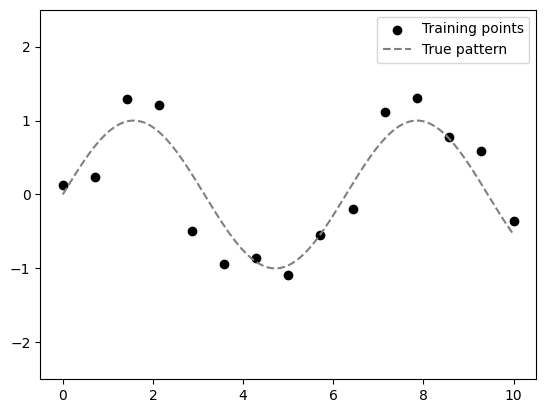

In [ ]:
import matplotlib.pyplot as plt

grid = np.linspace(0, 10, 500).reshape(-1, 1)


def plot_fit(model=None, label=None):
    plt.scatter(X_train, y_train, color="black", label="Training points")
    plt.plot(grid, np.sin(grid), color="gray", linestyle="--", label="True pattern")
    if model is not None:
        plt.plot(grid, model.predict(grid), color="tab:red", label=label)
    plt.ylim(-2.5, 2.5)
    plt.legend()
    plt.show()


plot_fit()

## Too flexible: a polynomial of degree 12

`PolynomialFeatures(degree=12)` turns the single feature $x$ into $x, x^2, \dots, x^{12}$, and a linear regression then fits one weight to each. The powers are standardised first, for a reason that matters below:

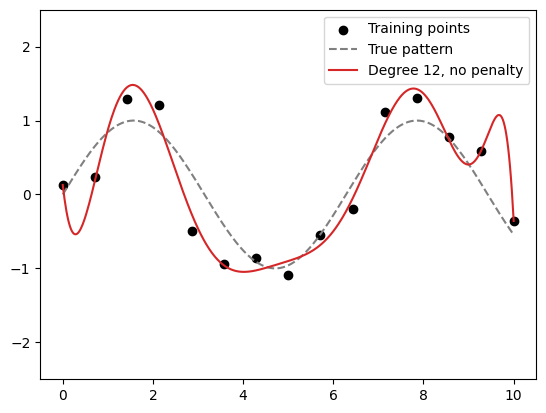

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


def polynomial_model(regressor):
    return make_pipeline(PolynomialFeatures(degree=12, include_bias=False), StandardScaler(), regressor)


def errors(model):
    return pd.Series({
        "training MAE": mean_absolute_error(y_train, model.predict(X_train)),
        "held-out MAE": mean_absolute_error(y_held_out, model.predict(X_held_out)),
    }).round(3)


unpenalised = polynomial_model(LinearRegression()).fit(X_train, y_train)
plot_fit(unpenalised, "Degree 12, no penalty")

In [ ]:
errors(unpenalised)

training MAE    0.114
held-out MAE    0.482
dtype: float64

Twelve weights and an intercept for fifteen points: the curve passes close to every one, and bends between them to do so, most of all near the edges. Its weights show how:

In [ ]:
pd.Series(unpenalised[-1].coef_, index=[f"x^{power}" for power in range(1, 13)]).round(1)

x^1       -16.6
x^2       421.7
x^3     -3054.7
x^4      9554.1
x^5    -12977.6
x^6      2284.7
x^7      9882.5
x^8     -1103.5
x^9     -9455.2
x^10    -1647.7
x^11    10850.0
x^12    -4737.8
dtype: float64

Weights in the thousands, alternating in sign. The twelve powers of one feature are nearly copies of one another (after standardising, $x^{11}$ and $x^{12}$ are almost perfectly correlated), so least squares can trade large positive and negative weights that nearly cancel at the training points. Between the points they don't cancel, and the curve bends. The training error is small (0.11) and the held-out error about four times larger (0.48): overfitting, as in [Overfitting and the train/test split](overfitting_and_the_split.ipynb).

## A penalty on the weights

**Ridge** regression changes what is minimised. Instead of the squared error alone, it minimises

$$\sum_i (y_i - \hat{y}_i)^2 + \alpha \sum_j w_j^2$$

the squared error *plus* the sum of the squared weights, multiplied by a setting $\alpha$. Large weights now cost something, so the model uses them only where they reduce the error by more than they cost. With $\alpha = 0$ it is ordinary least squares; as $\alpha$ grows, every weight is pulled towards 0, until the model is a flat line at the mean. The intercept is not penalised.

This is why the powers were standardised: the penalty treats all weights alike, and a weight's size depends on its feature's scale. Without scaling, the penalty would fall hardest on the features with the smallest spread, for no reason related to their usefulness.

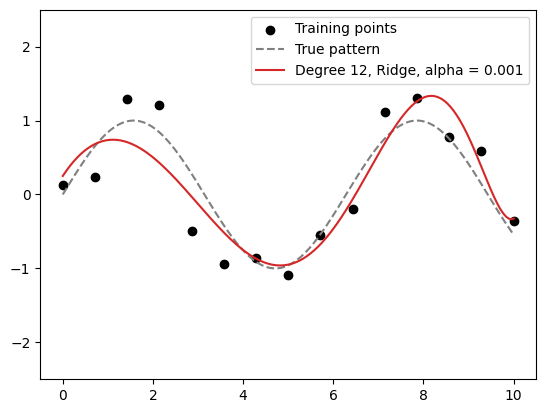

In [ ]:
from sklearn.linear_model import Ridge

ridge = polynomial_model(Ridge(alpha=0.001)).fit(X_train, y_train)
plot_fit(ridge, "Degree 12, Ridge, alpha = 0.001")

In [ ]:
errors(ridge)

training MAE    0.292
held-out MAE    0.376
dtype: float64

In [ ]:
pd.Series(ridge[-1].coef_, index=[f"x^{power}" for power in range(1, 13)]).round(2)

x^1      2.86
x^2    -15.17
x^3      8.87
x^4     11.68
x^5      4.51
x^6     -2.59
x^7     -6.27
x^8     -6.54
x^9     -4.45
x^10    -1.14
x^11     2.46
x^12     5.72
dtype: float64

Even a small penalty, $\alpha = 0.001$, brings every weight below 16 in size, and the curve follows the sine instead of the noise. The training error rises (from 0.11 to 0.29) because the model no longer chases every point, and the held-out error falls (from 0.48 to 0.38): the trade the penalty is for.

## Lasso

**Lasso** penalises the absolute values of the weights instead of their squares:

$$\sum_i (y_i - \hat{y}_i)^2 + \alpha \sum_j |w_j|$$

The difference has a striking consequence. A squared penalty barely charges a weight that is already small, so Ridge shrinks weights without ever making them exactly 0. An absolute penalty charges every unit of weight the same, so Lasso sets the least useful weights to exactly 0: it selects features as it fits. scikit-learn's `Lasso` scales the error term differently from `Ridge` (it divides by twice the number of rows), so their $\alpha$ values are not comparable.

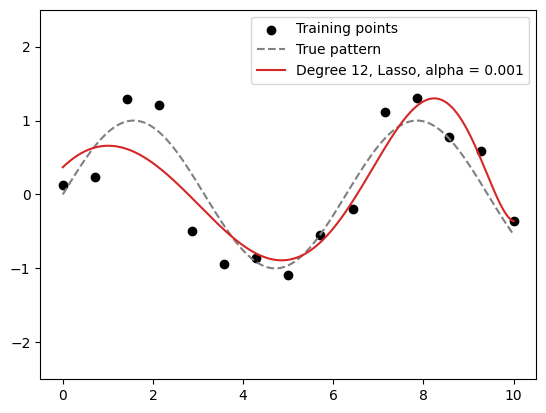

In [ ]:
from sklearn.linear_model import Lasso

lasso = polynomial_model(Lasso(alpha=0.001, max_iter=1_000_000)).fit(X_train, y_train)
plot_fit(lasso, "Degree 12, Lasso, alpha = 0.001")

In [ ]:
errors(lasso)

training MAE    0.315
held-out MAE    0.386
dtype: float64

In [ ]:
pd.Series(lasso[-1].coef_, index=[f"x^{power}" for power in range(1, 13)]).round(3)

x^1      1.817
x^2     -9.707
x^3      0.000
x^4     17.444
x^5      0.000
x^6     -0.000
x^7     -0.409
x^8    -15.265
x^9     -0.000
x^10    -0.000
x^11     0.000
x^12     6.038
dtype: float64

About the same held-out error as Ridge (0.39), with half of the weights exactly 0: Lasso has kept six of the twelve powers and dropped the rest. With many candidate features, of which only some matter, this makes Lasso a way to select features and a model that is easier to read.

## The penalty as a setting

$\alpha$ is chosen like the depth of a tree or the number of neighbours: by its error on data the model didn't learn from. Both errors for Ridge, over a wide range of $\alpha$ (a logarithmic axis, since the useful values span many orders of magnitude), with the held-out error of the unpenalised model as a dotted line:

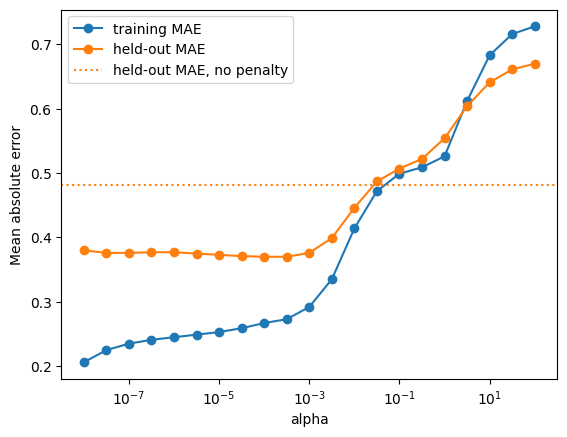

In [ ]:
alphas = np.logspace(-8, 2, 21)
ridge_errors = pd.DataFrame({alpha: errors(polynomial_model(Ridge(alpha=alpha)).fit(X_train, y_train)) for alpha in alphas}).T
ridge_errors.plot(marker="o", logx=True)
plt.axhline(errors(unpenalised)["held-out MAE"], color="tab:orange", linestyle=":", label="held-out MAE, no penalty")
plt.legend()
plt.xlabel("alpha")
plt.ylabel("Mean absolute error")
plt.show()

Read from left to right, from almost no penalty to a very strong one. At the far left the model is nearly unpenalised, yet its held-out error (0.38) is already far below the dotted line of no penalty at all (0.54): even a tiny $\alpha$ stops the huge cancelling weights. The held-out error is lowest around $\alpha = 10^{-4}$, and from $10^{-3}$ on both errors rise together: the penalty flattens the curve until it can no longer follow the sine, and the model underfits. Training and held-out errors meet for large $\alpha$, the mark of a model too rigid to overfit.

Every model has such a setting, and they all work the same way:

| Model | Setting | More flexible when the setting is |
| --- | --- | --- |
| Decision tree | `max_depth` | larger |
| Random forest | `min_samples_leaf` | smaller |
| k-nearest neighbours | `n_neighbors` | smaller |
| Linear model with powers of the features | `degree` | larger |
| Ridge, Lasso | `alpha` | smaller |
| Logistic regression, support vector machines | `C`, the inverse of a penalty | larger |

None of them has a right value in general: it depends on the data, and is found on a validation set ([Validation and model selection](validation_and_model_selection.ipynb)) or by cross-validation ([Cross-validation and hyperparameter search](cross_validation_and_search.ipynb)). Choosing it by the held-out error, as above, has the usual cost: that error is no longer an honest estimate.

**Elastic net** combines both penalties, with a second setting for the mix; the penalties of neural networks (*weight decay*) are the Ridge penalty under another name when the network is trained by plain gradient descent; adaptive optimisers such as AdamW apply it in a slightly different way.